# 02. Classical models and the Session 1 forecast

In [5]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import *

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160, "display.max_columns", 40)
data, weather_fc = load_data()
y = data["y"].to_numpy(float)
FEATURES = [c for c in weather_fc.columns if c != "ds"]
print(len(data), "hours, last one:", data["ds"].iloc[-1])

import time
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import MSTL
from statsforecast.models import AutoARIMA

WINDOWS = 10         # no overlap, the last 20 days
UNI_DAYS = 28        # univariate models see 4 weeks: the level changes too fast for more

33480 hours, last one: 2026-10-27 00:00:00


## The models

Each function takes the history and returns the forecast with its 95% bounds, so the backtest can treat them alike.

In [6]:
def ets_fc(hist, h=H):
    # Holt-Winters as ETS(A,Ad,A): damped trend, because a 4-week trend should not run on
    hist = pd.Series(hist)
    fit = ETSModel(hist, error="add", trend="add", damped_trend=True, seasonal="add", seasonal_periods=24).fit(disp=False)
    pred = fit.get_prediction(start=len(hist), end=len(hist) + h - 1).summary_frame(alpha=0.05)
    point = np.clip(pred["mean"].to_numpy(), 0, None)
    return point, np.clip(pred["pi_lower"].to_numpy(), 0, None), np.maximum(pred["pi_upper"].to_numpy(), point)

def sarima_fc(hist, h=H):
    # SARIMA(1,0,1)(0,1,1)_24: the seasonal difference removes the daily cycle
    fc = SARIMAX(hist, order=(1, 0, 1), seasonal_order=(0, 1, 1, 24)).fit(disp=False).get_forecast(h)
    ci, point = fc.conf_int(alpha=0.05), np.clip(fc.predicted_mean, 0, None)
    return point, np.clip(ci[:, 0], 0, None), np.maximum(ci[:, 1], point)

def autosarima_fc(hist, h=H):
    # Automatic check of the manual order; the search is limited so one window takes seconds
    out = AutoARIMA(season_length=24, max_p=2, max_q=2, max_P=1, max_Q=1, stepwise=True,
                    approximation=True).fit(np.asarray(hist, float)).predict(h=h, level=[95])
    point = np.clip(out["mean"], 0, None)
    return point, np.minimum(np.clip(out["lo-95"], 0, None), point), np.maximum(out["hi-95"], point)

def mstl_fc(hist, h=H):
    # MSTL: the seasonal parts repeat their last cycle, ARIMA forecasts what is left
    res = MSTL(hist, periods=(24, 168)).fit()
    seas = res.seasonal
    future = sum(np.array([seas[-m:, j][i % m] for i in range(h)]) for j, m in enumerate((24, 168)))
    fc = SARIMAX(hist - seas.sum(axis=1), order=(1, 0, 1), trend="c").fit(disp=False).get_forecast(h)
    ci, point = fc.conf_int(alpha=0.05), np.clip(fc.predicted_mean + future, 0, None)
    return point, np.clip(ci[:, 0] + future, 0, None), np.maximum(ci[:, 1] + future, point)

## Backtest

The windows do not overlap and DynReg gets the **actual** weather of each window, because we have no
archived forecasts. Its scores are therefore optimistic, and that matters below.

In [7]:
UNIVARIATE = {"ETS": ets_fc, "SARIMA": sarima_fc, "AutoSARIMA": autosarima_fc, "MSTL": mstl_fc}
frames = []
t0 = time.time()
for k, past_df, test_df in origins(data, WINDOWS):
    hist = past_df["y"].to_numpy(float)
    b, d = snaive(hist), dynreg(past_df.iloc[-DYNREG_DAYS * 24:], test_df)
    frame = pd.DataFrame({"window": k, "step": np.arange(1, H + 1), "actual": test_df["y"].to_numpy(float),
                          "benchmark": b[0], "benchmark lo": b[1], "benchmark hi": b[2],
                          "DynReg": d[0], "DynReg lo": d[1], "DynReg hi": d[2]})
    for name, model in UNIVARIATE.items():
        frame[name], frame[f"{name} lo"], frame[f"{name} hi"] = model(hist[-UNI_DAYS * 24:])
    for suffix in ("", " lo", " hi"):        # the Session 1 file averaged the two, bounds included
        frame[f"DynReg+SNAIVE{suffix}"] = (frame[f"DynReg{suffix}"] + frame[f"benchmark{suffix}"]) / 2
    frames.append(frame)
bt = pd.concat(frames, ignore_index=True)
print(f"{time.time() - t0:.0f} s")

52 s


In [9]:
COLUMNS = ["ETS", "SARIMA", "AutoSARIMA", "MSTL", "DynReg", "DynReg+SNAIVE", "benchmark"]
summary = {}
for metric in ("RMSE", "MAPE", "Winkler"):
    table = window_table(bt, COLUMNS, metric)
    summary[metric] = table["mean"].round(1)
    summary[f"{metric} wins"] = table["beats benchmark"]
pd.DataFrame(summary)

,RMSE,RMSE wins,MAPE,MAPE wins,Winkler,Winkler wins
ETS,344.3,3,407.2,4,2314.6,4
SARIMA,301.9,5,331.4,5,1386.0,6
AutoSARIMA,314.9,4,316.9,6,1419.2,5
MSTL,380.3,3,743.3,4,4747.6,3
DynReg,250.5,8,223.2,6,1111.2,9
DynReg+SNAIVE,217.2,9,313.7,7,1109.5,9
benchmark,281.4,0,424.9,0,2020.2,0


## The same scores on day 2

The private ranking uses hours 25-48 only, so day 2 gets its own table.

In [10]:
summary = {}
for metric in ("RMSE", "MAPE", "Winkler"):
    table = window_table(bt, COLUMNS, metric, first=25)
    summary[metric] = table["mean"].round(1)
    summary[f"{metric} wins"] = table["beats benchmark"]
pd.DataFrame(summary)

,RMSE,RMSE wins,MAPE,MAPE wins,Winkler,Winkler wins
ETS,358.2,4,371.2,1,2961.9,2
SARIMA,305.9,4,272.7,4,1463.7,5
AutoSARIMA,332.8,4,259.2,5,1574.7,4
MSTL,390.1,4,398.6,2,4653.1,3
DynReg,250.0,6,153.4,6,1274.4,8
DynReg+SNAIVE,225.4,9,224.1,7,1310.6,8
benchmark,305.6,0,316.9,0,2178.5,0


## The Session 1 forecast

This rebuilds the submitted file: DynReg on 60 days, fitted on the whole history and fed with
`weather_forecast.csv`, averaged with the benchmark. The check below compares it with values recorded
from the submitted file before it was replaced.

matches the recorded Session 1 values
format OK
peaks: DynReg 1887 / 1747, submitted file 1478 / 1423, last 4 days of history 1156 at most


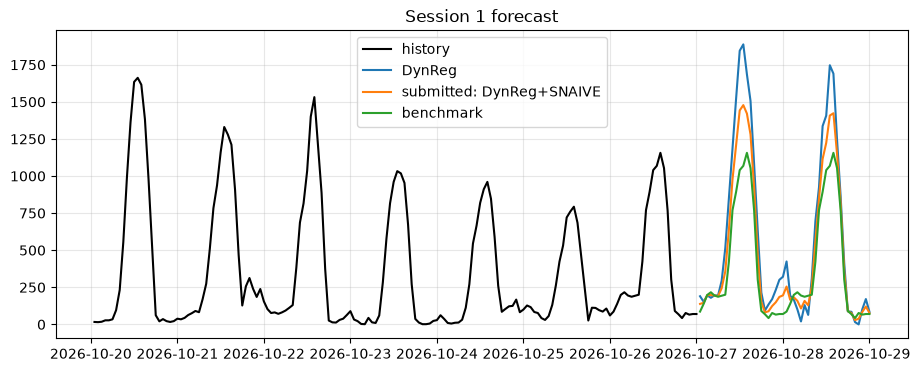

In [11]:
dyn = dynreg(data.iloc[-DYNREG_DAYS * 24:], weather_fc)
bench = snaive(y)
session1 = [(a + b) / 2 for a, b in zip(dyn, bench)]

RECORDED = {"2026-10-27 01:00:00": 138.0, "2026-10-27 13:00:00": 1477.9, "2026-10-27 16:00:00": 922.7,
            "2026-10-28 13:00:00": 1407.7, "2026-10-28 22:00:00": 83.5}
stamps = weather_fc["ds"].dt.strftime("%Y-%m-%d %H:%M:%S")
for stamp, value in RECORDED.items():
    assert abs(session1[0][stamps == stamp][0] - value) < 0.1, stamp
print("matches the recorded Session 1 values")

submission = pd.DataFrame({"ds": stamps, "forecast": session1[0], "lower_95": session1[1], "upper_95": session1[2]})
check_submission(submission, weather_fc["ds"])
submission.to_csv(f"{SURNAME}_session1.csv", index=False)
print(f"peaks: DynReg {dyn[0][:24].max():.0f} / {dyn[0][24:].max():.0f}, submitted file "
      f"{session1[0][:24].max():.0f} / {session1[0][24:].max():.0f}, last 4 days of history {data.tail(96)['y'].max():.0f} at most")

plt.plot(data["ds"].iloc[-7 * 24:], y[-7 * 24:], color="black", label="history")
plt.plot(weather_fc["ds"], dyn[0], label="DynReg")
plt.plot(weather_fc["ds"], session1[0], label="submitted: DynReg+SNAIVE")
plt.plot(weather_fc["ds"], bench[0], label="benchmark")
plt.legend(); plt.title("Session 1 forecast"); plt.show()

In [14]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120, "display.precision", 3)

SURNAME = "Akhlamova"   # <-- for your submission file name

if not SURNAME.strip():
    raise ValueError("Set SURNAME before running the rest.")

In [15]:
NEEDED = ["train.csv", "weather_forecast.csv"]

if not all(Path(f).exists() for f in NEEDED):
    try:
        from google.colab import files
        files.upload()                       # choose both files at once
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook.")

data = pd.read_csv("train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv("weather_forecast.csv", parse_dates=["ds"])

H = 48                                       # hours to forecast
M = 24                                       # the benchmark's season: one day
FUTURE = weather_fc["ds"]

assert len(FUTURE) == H and FUTURE.iloc[0] == data["ds"].iloc[-1] + pd.Timedelta(hours=1)
print(f"history: {len(data)} hours, {data['ds'].min()} to {data['ds'].max()}")
print(f"you are forecasting: {FUTURE.iloc[0]} to {FUTURE.iloc[-1]}")
data.tail()

history: 33480 hours, 2023-01-01 01:00:00 to 2026-10-27 00:00:00
you are forecasting: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
33475,2026-10-26 20:00:00,42.5,1.0,9,3,763,87,0,1.259
33476,2026-10-26 21:00:00,76.7,1.0,9,4,763,87,0,1.259
33477,2026-10-26 22:00:00,65.8,1.0,7,3,763,100,0,1.268
33478,2026-10-26 23:00:00,69.9,1.0,7,3,763,100,0,1.268
33479,2026-10-27 00:00:00,69.9,1.0,7,3,763,100,0,1.268


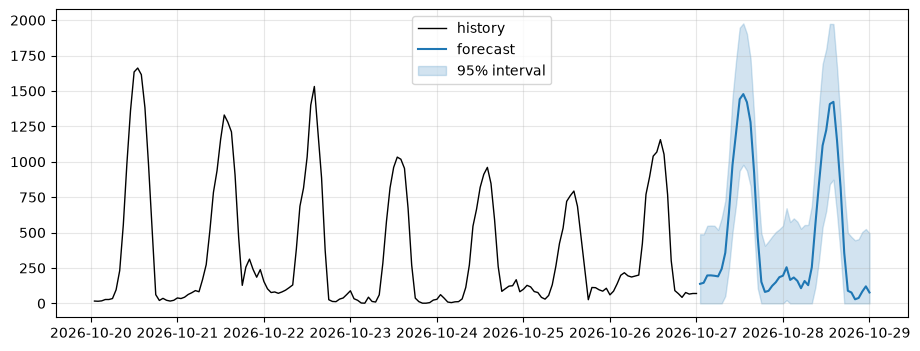

In [16]:
forecast, lower_95, upper_95 = [(np.asarray(a) + np.asarray(b)) / 2 for a, b in zip(dynreg(data.iloc[-60 * 24:], weather_fc), snaive(y))]

fig, ax = plt.subplots()
ax.plot(data["ds"].iloc[-7 * M:], y[-7 * M:], color="black", lw=1, label="history")
ax.plot(FUTURE, forecast, color="tab:blue", label="forecast")
ax.fill_between(FUTURE, lower_95, upper_95, color="tab:blue", alpha=0.2, label="95% interval")
ax.legend()
plt.show()

## What this means

- **Models without weather do not hold up.** On day 2, ETS, SARIMA, AutoSARIMA and MSTL beat the benchmark's RMSE
  in only 4 windows of 10.
- **The order search changes little.** AutoSARIMA is not better than the manual SARIMA (RMSE 333 against 306 on
  day 2), though its search was limited to stay fast.
- **The backtest favoured DynReg+SNAIVE,** with day 2 RMSE 225 and wins in 9 windows of 10, so it was submitted.
- **The submission told a different story.** On the first 24 hidden hours it scored RMSE 245.4, MAPE 99.7%,
  Winkler 716, while the benchmark scored RMSE 115.7, MAPE 84.3%, Winkler 521.
- **Why the backtest misled us.** It gave DynReg the actual weather. With `weather_forecast.csv`, DynReg peaks at
  1887 and 1747, above anything in the last 4 days of history (1156 at most). Nobody checked that peak before
  submitting.
- **What is not known.** The exact cause of the overshoot. Other training windows and cloud terms were tried in
  the working notebook and day 2 stayed at 1750-2150 in all 12 variants.